IN THE NAME OF GOD

Professor HAMED BAGHBAN

MACHINE LEARNING -PROJECT1
                             
MOHAMMAD MAHDI FARAJI


 imports:

In [121]:

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.cluster import KMeans
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

loading the <'synthetic_customer_behavior (1).csv'>  and check:

In [122]:
data = pd.read_csv('synthetic_customer_behavior (1).csv')


data.info()
print("\nPurchase Category Distribution:")
print(data['Purchase_Category'].value_counts())
print(data.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Feature_1               1000 non-null   float64
 1   Feature_2               1000 non-null   float64
 2   Feature_3               1000 non-null   float64
 3   Feature_4               1000 non-null   float64
 4   Feature_5               1000 non-null   float64
 5   Age                     1000 non-null   int64  
 6   Gender                  1000 non-null   object 
 7   Region                  1000 non-null   object 
 8   Purchase_Category       300 non-null    object 
 9   Purchase_Amount         1000 non-null   float64
 10  Time_Spent_on_Website   1000 non-null   float64
 11  Number_of_Items_Viewed  1000 non-null   int64  
dtypes: float64(7), int64(2), object(3)
memory usage: 93.9+ KB

Purchase Category Distribution:
Purchase_Category
Electronics    194
Clothing        50


Visualize missing values:


Missing data count in each column:
Feature_1                   0
Feature_2                   0
Feature_3                   0
Feature_4                   0
Feature_5                   0
Age                         0
Gender                      0
Region                      0
Purchase_Category         700
Purchase_Amount             0
Time_Spent_on_Website       0
Number_of_Items_Viewed      0
dtype: int64


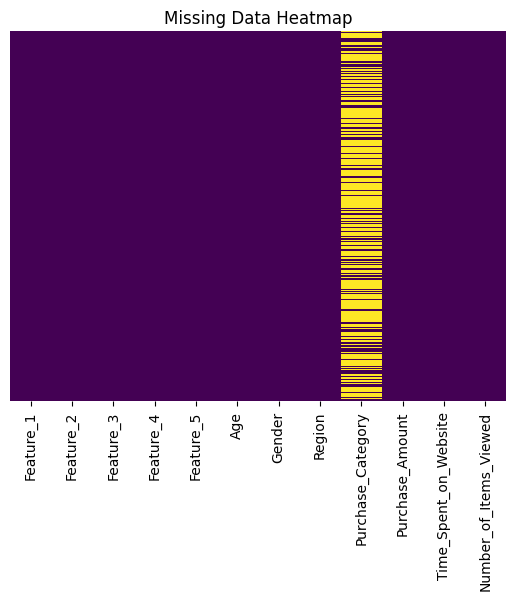

In [123]:
missing_data = data.isnull().sum()
print("\nMissing data count in each column:")
print(missing_data)

sns.heatmap(data.isnull(), yticklabels=False, cbar=False, cmap='viridis')
plt.title('Missing Data Heatmap')
plt.show()

# Split the data into rows with and without missing Purchase Category
missing_data = data[data['Purchase_Category'].isna()]
complete_data = data[~data['Purchase_Category'].isna()]

Encode categorical features:

<ipython-input-124-5d820fece6e2>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  complete_data[['Gender', 'Region', 'Purchase_Category']] = encoder.fit_transform(complete_data[['Gender', 'Region', 'Purchase_Category']])
<ipython-input-124-5d820fece6e2>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  missing_data[['Gender', 'Region']] = encoder.fit_transform(missing_data[['Gender', 'Region']])


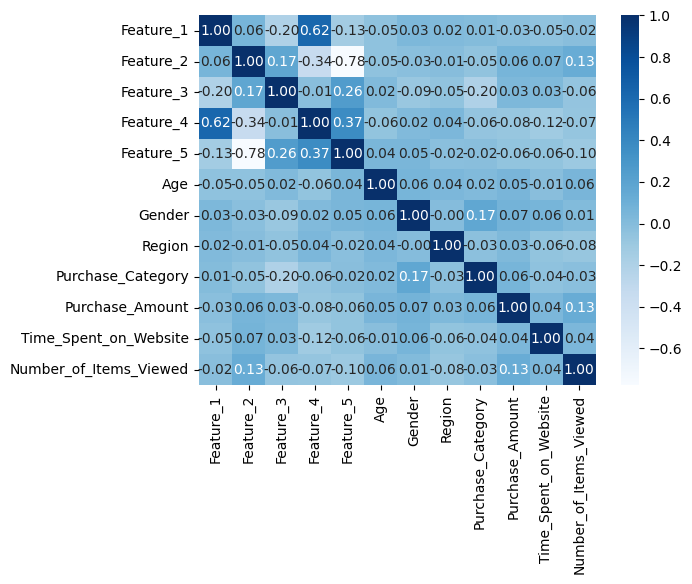

In [124]:
encoder = OrdinalEncoder()
complete_data[['Gender', 'Region', 'Purchase_Category']] = encoder.fit_transform(complete_data[['Gender', 'Region', 'Purchase_Category']])

# Encode the missing data of gender and region:
missing_data[['Gender', 'Region']] = encoder.fit_transform(missing_data[['Gender', 'Region']])

import seaborn as sns
import matplotlib.pyplot as plt
#heatmap
sns.heatmap(complete_data.corr(), annot=True, cmap='Blues', fmt='.2f')
plt.show()


Select features and target:

In [125]:
X = complete_data[['Feature_2', 'Feature_3', 'Feature_4', 'Age', 'Gender', 'Region', 'Time_Spent_on_Website', 'Number_of_Items_Viewed']]
y = complete_data['Purchase_Category']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


Decision Tree Classifier


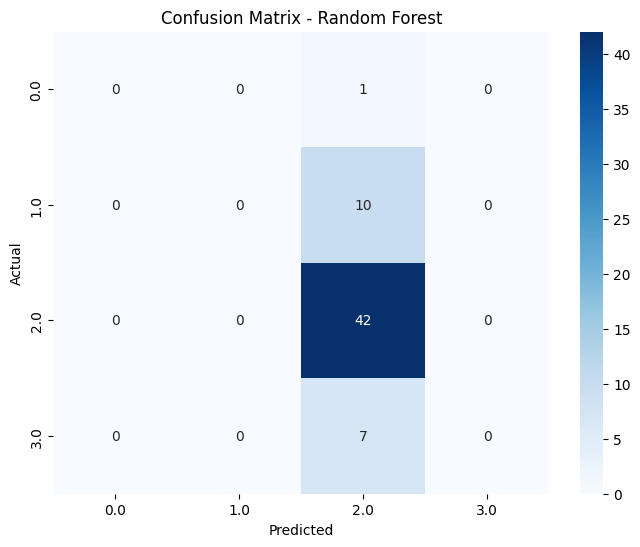


Decision Tree Accuracy: 0.65
Decision Tree F1-Score: 0.5515151515151514


In [126]:
dt_classifier = DecisionTreeClassifier(criterion='entropy', max_depth=4)
dt_classifier.fit(X_train, y_train)


#Compute the confusion matrix and plot:
dt_pred = dt_classifier.predict(X_test)
cm = confusion_matrix(y_test, rf_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y_test), yticklabels=np.unique(y_test))
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Decision Tree Results
print("\nDecision Tree Accuracy:", accuracy_score(y_test, dt_pred))
print("Decision Tree F1-Score:", f1_score(y_test, dt_pred, average='weighted'))

random forest:

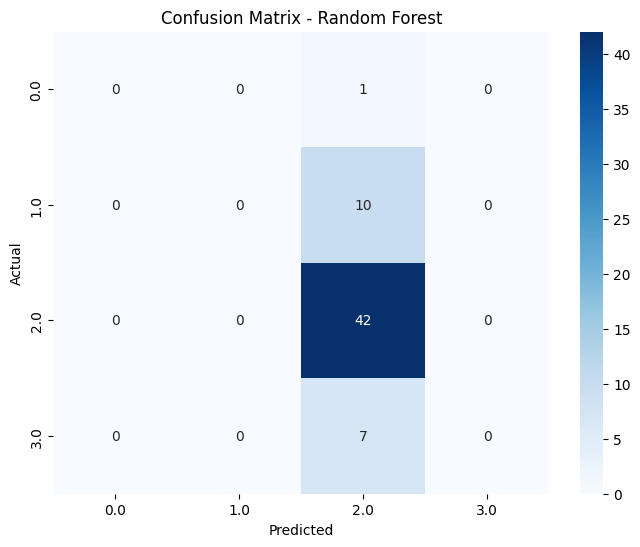


Random Forest Accuracy: 0.7
Random Forest F1-Score: 0.5764705882352941


In [127]:
# Train Random Forest Classifier
rf_classifier = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
rf_classifier.fit(X_train, y_train)

#Compute the confusion matrix and plot:
rf_pred = rf_classifier.predict(X_test)
cm = confusion_matrix(y_test, rf_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y_test), yticklabels=np.unique(y_test))
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# Results
print("\nRandom Forest Accuracy:", accuracy_score(y_test, rf_pred))
print("Random Forest F1-Score:", f1_score(y_test, rf_pred, average='weighted'))

# Predict missing Purchase Category using Random Forest
missing_features = missing_data[['Feature_2', 'Feature_3', 'Feature_4', 'Age', 'Gender', 'Region', 'Time_Spent_on_Website', 'Number_of_Items_Viewed']]

# Ensure missing_data is not a view, create a copy if necessary
missing_data = missing_data.copy()

# Use .loc to avoid SettingWithCopyWarning and ensure proper assignment
missing_data.loc[:, 'Purchase_Category'] = rf_classifier.predict(missing_features)

# Now missing_data will have the predicted 'Purchase_Category' without any warnings


Combine the datasets


In [128]:
final_dataset = pd.concat([complete_data, missing_data])

# Save the final dataset to a CSV
final_dataset.to_csv('final_processed_data.csv', index=False)

plot the results:

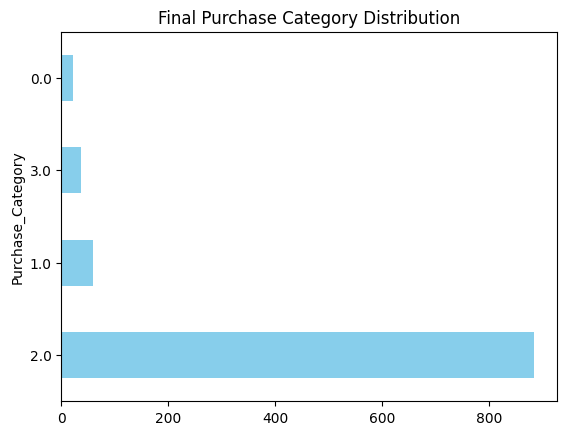

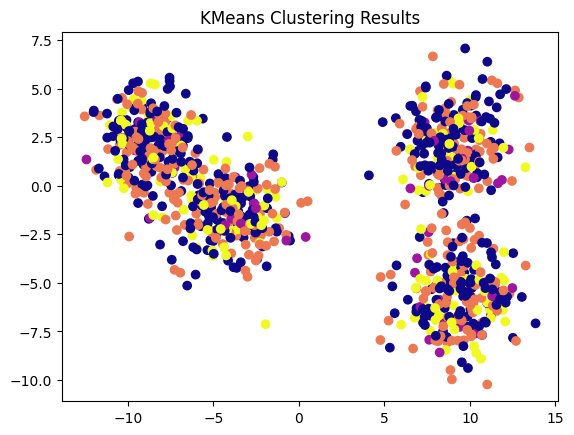

In [129]:
import matplotlib.pyplot as plt
final_dataset['Purchase_Category'].value_counts().plot(
    kind='barh',        #  افقی
    color='skyblue',
    title="Final Purchase Category Distribution"
)
plt.show()



import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
# Apply KMeans with 4 clusters
kmeans = KMeans(n_clusters=4, random_state=42)
kmeans.fit(final_dataset[numerical_columns])

# Visualize the clusters
plt.scatter(final_dataset['Feature_2'], final_dataset['Feature_4'], c=kmeans.labels_, cmap='plasma')
plt.title("KMeans Clustering Results")
plt.show()

Build and train a Neural Network model:


In [130]:
X_val, y_val = X_test[:len(X_test)//2], y_test[:len(y_test)//2]
X_test, y_test = X_test[len(X_test)//2:], y_test[len(y_test)//2:]

nn_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(len(np.unique(y_train)), activation='softmax')
])

nn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
nn_model.fit(X_train, y_train, epochs=30, validation_data=(X_val, y_val), verbose=1)

# Evaluate Neural Network
nn_model.evaluate(X_test, y_test)

# Neural Network Predictions
nn_predictions = nn_model.predict(X_test)
predicted_classes = np.argmax(nn_predictions, axis=1)
print("Neural Network Predictions:", predicted_classes)


/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.4332 - loss: 5.0917 - val_accuracy: 0.7000 - val_loss: 1.5934
Epoch 2/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4696 - loss: 3.4485 - val_accuracy: 0.6667 - val_loss: 1.1396
Epoch 3/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4249 - loss: 3.3718 - val_accuracy: 0.6000 - val_loss: 1.0698
Epoch 4/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4397 - loss: 2.6246 - val_accuracy: 0.6333 - val_loss: 1.0305
Epoch 5/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4293 - loss: 2.4231 - val_accuracy: 0.7000 - val_loss: 1.0271
Epoch 6/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4637 - loss: 1.8818 - val_accuracy: 0.6667 - val_loss: 1.0684
Epoch 7/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4442 - loss: 1.9521 - val_accuracy: 0.6000 - val_loss: 1.1660
Epoch 8/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.4971 - loss: 1.6528 - val_accuracy: 0.3333 - val_loss: 1.2756
Ep